# Lab 7: Naive Bayes — Spam Detection & Sentiment Analysis
**Week 7 — Fall 2026 — BS Computer Science, 5th Semester**

---
### Student Info
- **Name:** Amir Khan
- **CMS ID:** 023-24-0166
- **Program / Section:** BSCS, Section F
- **GitHub Profile:** https://github.com/Amir-Khan11
- **Kaggle Profile:** https://www.kaggle.com/amirkhan123123
- **Datasets used:**
  - SMS Spam Collection (`spam.csv`) — Task A
  - Twitter US Airline Sentiment (`Tweets.csv`) — Task B

---



In [ ]:
# Upload spam.csv and Tweets.csv into the Colab session
from google.colab import files
uploaded = files.upload()

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

# Fixed random seed for reproducibility
RANDOM_STATE = 42

pd.set_option('display.max_colwidth', 100)

---
## Part 1 — Problem Definition & Dataset Exploration

In this part I explored both datasets before cleaning or modelling anything: how many rows each contains, what a single row represents, and how balanced the target classes are. Class balance matters because it determines which evaluation metric can be trusted later, since accuracy can be misleading on imbalanced data.

In [4]:
# Load the SMS spam dataset
# The file has some extra junk columns and a non-UTF8 encoding, which is why I use 'latin-1'
spam_df = pd.read_csv('spam.csv', encoding='latin-1')

# Keep only the two useful columns and rename them to something readable
spam_df = spam_df[['v1', 'v2']]
spam_df.columns = ['label', 'message']

print("Spam dataset shape:", spam_df.shape)
spam_df.head()

Spam dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [5]:
# Class balance for the spam dataset (counts and percentages)
spam_counts = spam_df['label'].value_counts()
spam_pct = spam_df['label'].value_counts(normalize=True) * 100

print("Counts:\n", spam_counts)
print("\nPercentages:\n", spam_pct.round(2))


Counts:
 label
ham     4825
spam     747
Name: count, dtype: int64

Percentages:
 label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


In [6]:
# Load the airline tweets dataset
tweets_df = pd.read_csv('Tweets.csv')

print("Tweets dataset shape:", tweets_df.shape)
tweets_df[['airline_sentiment', 'text']].head()


Tweets dataset shape: (14640, 15)


,airline_sentiment,text
0,neutral,@VirginAmerica What @dhepburn said.
1,positive,@VirginAmerica plus you've added commercials to the experience... tacky.
2,neutral,@VirginAmerica I didn't today... Must mean I need to take another trip!
3,negative,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &..."
4,negative,@VirginAmerica and it's a really big bad thing about it


In [7]:
# Class balance for the full tweets dataset (positive / negative / neutral)
tweet_counts = tweets_df['airline_sentiment'].value_counts()
tweet_pct = tweets_df['airline_sentiment'].value_counts(normalize=True) * 100

print("Counts:\n", tweet_counts)
print("\nPercentages:\n", tweet_pct.round(2))


Counts:
 airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

Percentages:
 airline_sentiment
negative    62.69
neutral     21.17
positive    16.14
Name: proportion, dtype: float64


In [8]:
# This task is binary (positive vs negative), so I drop the neutral rows
tweets_df = tweets_df[tweets_df['airline_sentiment'] != 'neutral'].reset_index(drop=True)

print("Rows remaining after dropping neutral tweets:", tweets_df.shape[0])
tweets_df['airline_sentiment'].value_counts()

Rows remaining after dropping neutral tweets: 11541


,count
airline_sentiment,
negative,9178
positive,2363


### ✏️ Interpretation

**Spam dataset (SMS):**
- **A single row represents:** one SMS text message, labeled `ham` (legitimate) or `spam` (unwanted/promotional).
- **Practical problem this model supports:** automatically filtering unwanted promotional or scam texts out of a user's inbox before the user ever sees them.
- **Why it is binary classification:** every message belongs to exactly one of two mutually exclusive classes, `ham` or `spam`.
- **Class balance:** the dataset is imbalanced, with 4,825 ham messages (86.59%) and only 747 spam messages (13.41%). Because of this, accuracy alone can be misleading, so I give more weight to precision, recall, and F1-score.

**Sentiment dataset (Tweets):**
- **A single row represents:** one tweet directed at a US airline, labeled with the sentiment it expresses (`positive`, `negative`, or `neutral`).
- **Practical problem this model supports:** an airline's social-media or customer-service team could use it to automatically flag negative tweets for priority response and to track overall customer sentiment.
- **Why it is binary classification (after dropping neutral):** once the `neutral` tweets are removed and only `positive` and `negative` remain, every remaining row falls into exactly one of two classes.
- **Class balance:** the full dataset is 62.69% negative, 21.17% neutral, and 16.14% positive, so airline tweets skew heavily negative (people mostly tweet at airlines to complain). After dropping neutral tweets, the two-class dataset is still imbalanced: 9,178 negative (79.53%) versus 2,363 positive (20.47%).
- **Rows remaining after dropping neutral:** **11,541**.

---
## Part 2 — Task A: Text Cleaning & Vectorization (Spam)

Models cannot read raw text, so the messages have to be converted into numbers. In this part I:
1. lightly cleaned the message text (lowercasing and removing punctuation),
2. encoded the label (`ham`/`spam`) as 0/1,
3. split the data into training and test sets, and
4. fitted a TF-IDF vectorizer **only on the training data** and used it to transform both the training and test sets.

**Why fit only on training data?** If the vectorizer were fitted on the whole dataset (including the test set), the vocabulary and word-frequency statistics would "see" the test data before training even begins. That is a form of data leakage: it makes test performance look better than it would be on truly unseen messages.

In [9]:
import re

def clean_text(text):
    text = str(text).lower()              # lowercase everything
    text = re.sub(r'[^a-z0-9\s]', ' ', text)  # remove punctuation/special characters
    text = re.sub(r'\s+', ' ', text).strip()  # collapse extra whitespace
    return text

spam_df['clean_message'] = spam_df['message'].apply(clean_text)
spam_df[['message', 'clean_message']].head()


,message,clean_message
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g...",go until jurong point crazy available only in bugis n great world la e buffet cine there got amo...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...,free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005 text fa to 87121 to receive e...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives around here though",nah i don t think he goes to usf he lives around here though


In [10]:
# Encode labels: ham = 0, spam = 1
spam_df['label_num'] = spam_df['label'].map({'ham': 0, 'spam': 1})

X = spam_df['clean_message']
y = spam_df['label_num']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])


Train size: 4457  Test size: 1115


In [11]:
# Fit the vectorizer ONLY on training messages, then transform both sets
tfidf = TfidfVectorizer()
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print("Vocabulary size (number of features):", len(tfidf.vocabulary_))


Vocabulary size (number of features): 7658


### ✏️ Interpretation

- **Vocabulary size:** **7,658** unique words/features (from the training messages only).
- **Why I fit the vectorizer on training data only:** if I had fitted the vectorizer on the full dataset (including the test set), the vocabulary and IDF weights would have "seen" words and word-frequency statistics from the test messages before training. That is a form of data leakage, because it gives the model indirect information about the test set, so test performance would be artificially inflated and would no longer reflect how the model performs on truly unseen messages.

---
## Part 3 — Task A: Naive Bayes Model & Evaluation (Spam)

In this part I trained a **Multinomial Naive Bayes** classifier, which is the standard choice for word-count and TF-IDF features, and evaluated it using accuracy, precision, recall, F1-score, and a confusion matrix.

In [12]:
nb_spam = MultinomialNB()
nb_spam.fit(X_train_vec, y_train)

y_pred_spam = nb_spam.predict(X_test_vec)


In [13]:
acc = accuracy_score(y_test, y_pred_spam)
prec = precision_score(y_test, y_pred_spam)
rec = recall_score(y_test, y_pred_spam)
f1 = f1_score(y_test, y_pred_spam)

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")


Accuracy:  0.9605
Precision: 1.0000
Recall:    0.7047
F1-score:  0.8268


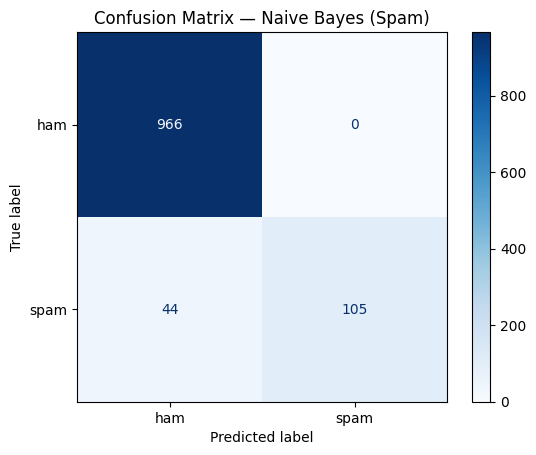

In [14]:
cm = confusion_matrix(y_test, y_pred_spam)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['ham', 'spam'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix — Naive Bayes (Spam)')
plt.show()


### ✏️ Interpretation

- **Accuracy: 0.9605** — about 96% of the test messages were classified correctly overall.
- **Precision: 1.0000** — of every message the model flagged as spam, 100% actually were spam (no ham message was wrongly flagged).
- **Recall: 0.7047** — the model caught only about 70% of the actual spam messages; the rest slipped through to the inbox.
- **F1-score: 0.8268** — the harmonic mean of precision and recall, which reflects the gap between a perfect precision and a middling recall.
- **Confusion matrix:** there were **0 false positives** (no ham message was wrongly flagged as spam) and **44 false negatives** (44 spam messages were missed and reached the inbox), out of 1,115 test messages (966 ham correctly kept and 105 spam correctly caught).

**Which error is worse for spam filtering?**
In my view, a false positive (a legitimate message wrongly hidden as spam) is usually worse than a false negative (a spam message that reaches the inbox). If a job offer, an OTP code, or a message from a client is silently moved to a spam folder that is rarely checked, the consequences can be serious and hard to notice, whereas an unwanted spam message in the inbox is a minor annoyance that can be deleted in a second. My model already reflects this priority: it achieved perfect precision (1.0) at the cost of recall (0.70), which means it is conservative about labelling a message as spam. For this reason, if I were to tune the model further, I would prioritize **precision** (for example, by keeping the classification threshold high) so that false positives stay at zero, even if that means a few more spam messages get through.

---
## Part 4 — Task A: Word Interpretation (Spam)

Naive Bayes learns a log-probability for every word given each class, stored in `feature_log_prob_`. In this part I examined the words with the largest gap between the spam and ham log-probabilities to see what the model actually learned to associate with spam.

In [15]:
feature_names = np.array(tfidf.get_feature_names_out())

# feature_log_prob_ has shape (n_classes, n_features): row 0 = ham, row 1 = spam
log_prob_diff = nb_spam.feature_log_prob_[1] - nb_spam.feature_log_prob_[0]

top_spam_idx = np.argsort(log_prob_diff)[-15:][::-1]
top_ham_idx = np.argsort(log_prob_diff)[:15]

top_spam_words = pd.DataFrame({
    'word': feature_names[top_spam_idx],
    'log_prob_diff': log_prob_diff[top_spam_idx]
})
top_ham_words = pd.DataFrame({
    'word': feature_names[top_ham_idx],
    'log_prob_diff': log_prob_diff[top_ham_idx]
})

print("Top 15 words most associated with SPAM:")
display(top_spam_words)

print("\nTop 15 words most associated with HAM:")
display(top_ham_words)


Top 15 words most associated with SPAM:


,word,log_prob_diff
0,claim,3.469874
1,prize,3.266109
2,150p,3.003695
3,www,3.000298
4,uk,2.899588
5,tone,2.863985
6,18,2.808092
7,guaranteed,2.787921
8,cs,2.753827
9,1000,2.729885



Top 15 words most associated with HAM:


,word,log_prob_diff
0,gt,-3.205885
1,lt,-3.195171
2,my,-3.175798
3,ok,-3.140837
4,ll,-3.098454
5,later,-3.034266
6,lor,-2.976343
7,da,-2.937991
8,but,-2.864343
9,home,-2.864283


In [16]:
# Custom test messages to check how the trained model handles new text
test_messages = [
    "WINNER!! You have been selected to receive a FREE cash prize, click now to claim!!!",
    "Hey, are we still on for lunch tomorrow?",
    "URGENT: your account has been suspended, verify your details immediately"
]

test_clean = [clean_text(m) for m in test_messages]
test_vec = tfidf.transform(test_clean)
test_pred = nb_spam.predict(test_vec)

for msg, pred in zip(test_messages, test_pred):
    label = 'SPAM' if pred == 1 else 'HAM'
    print(f"[{label}]  {msg}")

[SPAM]  WINNER!! You have been selected to receive a FREE cash prize, click now to claim!!!
[HAM]  Hey, are we still on for lunch tomorrow?
[HAM]  URGENT: your account has been suspended, verify your details immediately


### ✏️ Interpretation

- **Do the top spam and ham words match my intuition?** Yes, largely. The top spam-associated words — `claim`, `prize`, `150p`, `www`, `uk`, `tone`, `guaranteed`, `1000`, `nokia`, `500`, `txt`, and `service` — are the kind of vocabulary used in UK premium-rate SMS scams and prize/competition spam: money amounts, "claim your prize" language, premium-rate pricing (`150p`), and promotional links. The top ham-associated words — `my`, `ok`, `later`, `lor`, `he`, `sorry`, `me`, `how`, `come`, and `home` — are casual, personal, conversational words that I would expect in everyday texting between friends and family, which matches my intuition well.
- **Were my own test messages classified as I expected?** Two out of three matched my expectations. The obvious prize-scam message was correctly predicted as **SPAM**, and the casual lunch message was correctly predicted as **HAM**. However, the "URGENT: your account has been suspended, verify your details immediately" message was predicted as **HAM**, which I did not expect. Words such as "urgent", "account", "suspended", and "verify" were not among the top 15 spam-associated words, and the likely reason is that the spam examples in this dataset are dominated by prize, competition, and premium-rate SMS wording rather than account-security phishing language. This illustrates a real limitation of the model's vocabulary coverage.

---
## Part 5 — Task A: Kaggle Notebook Submission

I completed Task A (spam detection with Naive Bayes) in a separate Kaggle notebook and published it.

**Task A Kaggle Notebook URL:** [https://www.kaggle.com/code/amirkhan123123/notebookad7c0909fb?scriptVersionId=362886109](https://www.kaggle.com/code/amirkhan123123/notebookad7c0909fb?scriptVersionId=362886109)

---
## Part 6 — Task B: Text Cleaning & Vectorization (Sentiment)

In this part I repeated the same pipeline on the airline tweets. Tweets are messier than SMS messages because they contain `@mentions`, links, and `#hashtags` that are not useful words on their own, so I decided how much additional cleaning was worthwhile.

In [25]:
def clean_tweet(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)   # remove links
    text = re.sub(r'@\w+', ' ', text)              # remove @mentions (airline handles, usernames)
    text = re.sub(r'#', ' ', text)                 # keep hashtag words but drop the '#' symbol
    text = re.sub(r'[^a-z0-9\s]', ' ', text)        # remove remaining punctuation
    text = re.sub(r'\s+', ' ', text).strip()
    return text

tweets_df['clean_text'] = tweets_df['text'].apply(clean_tweet)
tweets_df[['text', 'clean_text']].head()


,text,clean_text
0,@VirginAmerica plus you've added commercials to the experience... tacky.,plus you ve added commercials to the experience tacky
1,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &...",it s really aggressive to blast obnoxious entertainment in your guests faces amp they have littl...
2,@VirginAmerica and it's a really big bad thing about it,and it s a really big bad thing about it
3,@VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.\nit's r...,seriously would pay 30 a flight for seats that didn t have this playing it s really the only bad...
4,"@VirginAmerica yes, nearly every time I fly VX this “ear worm” won’t go away :)",yes nearly every time i fly vx this ear worm won t go away


In [26]:
# Encode labels: negative = 0, positive = 1
tweets_df['label_num'] = tweets_df['airline_sentiment'].map({'negative': 0, 'positive': 1})

Xt = tweets_df['clean_text']
yt = tweets_df['label_num']

Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    Xt, yt, test_size=0.2, random_state=RANDOM_STATE, stratify=yt
)

print("Train size:", Xt_train.shape[0], " Test size:", Xt_test.shape[0])


Train size: 9232  Test size: 2309


In [27]:
# Fit the vectorizer ONLY on training tweets, same discipline as Task A
tfidf_tweets = TfidfVectorizer()
Xt_train_vec = tfidf_tweets.fit_transform(Xt_train)
Xt_test_vec = tfidf_tweets.transform(Xt_test)

print("Vocabulary size (number of features):", len(tfidf_tweets.vocabulary_))


Vocabulary size (number of features): 10075


### ✏️ Interpretation

- **Vocabulary size for the tweet vectorizer:** **10,075** unique words/features (fitted on the training tweets only).
- **Cleaning decisions that went beyond what I did for SMS, and why:** for the tweets I additionally removed URLs and `@mentions` before vectorizing, and I removed the `#` character while keeping the hashtag word itself (e.g. `#delayed` becomes `delayed`). SMS messages rarely contain links or @-handles, but tweets contain them often (airline handles such as `@united`, shared links, and so on). These are mostly noise rather than signal about sentiment, and leaving the raw @mentions in would have added many individual handles and usernames to the vocabulary without adding useful information.

---
## Part 7 — Task B: Naive Bayes Model & Evaluation (Sentiment)

In this part I used the same model and the same metrics on the new dataset and then compared the results with Task A.

In [28]:
nb_tweets = MultinomialNB()
nb_tweets.fit(Xt_train_vec, yt_train)

yt_pred = nb_tweets.predict(Xt_test_vec)


In [29]:
acc_t = accuracy_score(yt_test, yt_pred)
prec_t = precision_score(yt_test, yt_pred)
rec_t = recall_score(yt_test, yt_pred)
f1_t = f1_score(yt_test, yt_pred)

print(f"Accuracy:  {acc_t:.4f}")
print(f"Precision: {prec_t:.4f}")
print(f"Recall:    {rec_t:.4f}")
print(f"F1-score:  {f1_t:.4f}")


Accuracy:  0.8311
Precision: 1.0000
Recall:    0.1755
F1-score:  0.2986


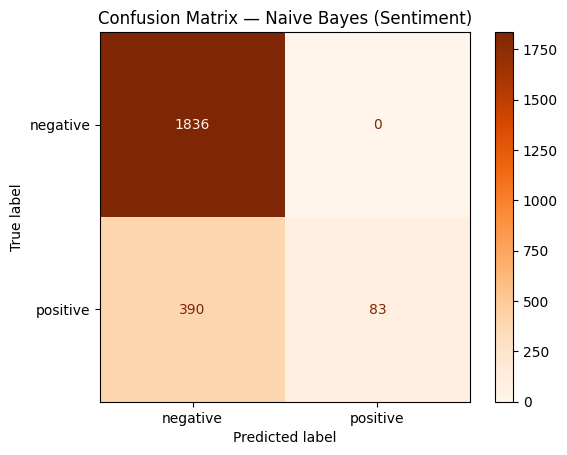

In [30]:
cm_t = confusion_matrix(yt_test, yt_pred)
disp_t = ConfusionMatrixDisplay(confusion_matrix=cm_t, display_labels=['negative', 'positive'])
disp_t.plot(cmap='Oranges')
plt.title('Confusion Matrix — Naive Bayes (Sentiment)')
plt.show()


### ✏️ Interpretation

- **Results on the sentiment test set:** Accuracy **0.8311**, Precision **1.0000**, Recall **0.1755**, F1-score **0.2986**.

**Comparison with Task A.** Naive Bayes performed noticeably *worse* on sentiment than on spam, especially in recall and F1-score (spam F1 = 0.8268 versus sentiment F1 = 0.2986). The accuracy of 0.8311 looks reasonable, but it is largely a result of the test set being dominated by the negative class: the model is very cautious about predicting "positive" (precision of 1.0), so it still scores a high accuracy while missing most of the positive tweets (a recall of only 0.1755 means it found barely 1 in 6 genuinely positive tweets).

Both datasets are imbalanced, and the spam data is actually more skewed (86.59% / 13.41%) than the sentiment data (79.53% / 20.47%), so imbalance alone does not explain the gap between the two tasks. I think the difference is better explained by how well the "naive" independence assumption fits each task. Spam SMS messages are short and formulaic, built from a fairly fixed vocabulary of prize, urgency, and money words that tend to co-occur with spam regardless of word order, so treating words as independent is a reasonable approximation. Tweets rely much more on context, negation (e.g. "not good"), sarcasm, and sentence-level tone, which a bag-of-words model cannot capture. The same word (e.g. "delay") can appear in a complaint and also in a relieved comment, and Naive Bayes has no way to tell these apart because it ignores word order and interactions between words.

---
## Part 8 — Task B: Kaggle Notebook Submission

I completed Task B (sentiment analysis with Naive Bayes) in a separate Kaggle notebook and published it.

**Task B Kaggle Notebook URL:** [https://www.kaggle.com/code/amirkhan123123/notebook6126e531e1?scriptVersionId=362890937](https://www.kaggle.com/code/amirkhan123123/notebook6126e531e1?scriptVersionId=362890937)

---
## Part 9 — Cross-Task Comparison & vs. Logistic Regression

First, I compared my two Naive Bayes results side by side in a table. Then I trained Logistic Regression on Task A's exact same TF-IDF features and compared it with Naive Bayes.

In [31]:
comparison_nb = pd.DataFrame({
    'Task': ['A - Spam', 'B - Sentiment'],
    'Accuracy': [acc, acc_t],
    'Precision': [prec, prec_t],
    'Recall': [rec, rec_t],
    'F1-score': [f1, f1_t]
})
comparison_nb


,Task,Accuracy,Precision,Recall,F1-score
0,A - Spam,0.960538,1.0,0.704698,0.826772
1,B - Sentiment,0.831096,1.0,0.175476,0.298561


In [24]:
# Logistic Regression on Task A's same vectorized features
logreg_spam = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logreg_spam.fit(X_train_vec, y_train)

y_pred_logreg = logreg_spam.predict(X_test_vec)

acc_lr = accuracy_score(y_test, y_pred_logreg)
prec_lr = precision_score(y_test, y_pred_logreg)
rec_lr = recall_score(y_test, y_pred_logreg)
f1_lr = f1_score(y_test, y_pred_logreg)

comparison_models = pd.DataFrame({
    'Model': ['Naive Bayes', 'Logistic Regression'],
    'Accuracy': [acc, acc_lr],
    'Precision': [prec, prec_lr],
    'Recall': [rec, rec_lr],
    'F1-score': [f1, f1_lr]
})
comparison_models


,Model,Accuracy,Precision,Recall,F1-score
0,Naive Bayes,0.960538,1.000000,0.704698,0.826772
1,Logistic Regression,0.972197,0.991667,0.798658,0.884758


### ✏️ Interpretation

- **Naive Bayes: Task A vs Task B.** Naive Bayes did clearly better on Task A (spam, F1 = 0.8268) than on Task B (sentiment, F1 = 0.2986), a difference of about 0.53 in F1-score. Spam messages are short and formulaic with a distinctive vocabulary, whereas sentiment depends on context, negation, and tone, for which the independence assumption is a poorer fit. Both tasks are imbalanced (86.59% / 13.41% for spam and 79.53% / 20.47% for sentiment), so I do not attribute the gap to class imbalance alone.
- **Naive Bayes vs Logistic Regression on Task A.** Logistic Regression outperformed Naive Bayes on accuracy (0.9722 vs 0.9605), recall (0.7987 vs 0.7047), and F1-score (0.8848 vs 0.8268), while Naive Bayes kept a slightly higher precision (1.0000 vs 0.9917). Logistic Regression's advantage came mainly from catching more of the spam messages (higher recall) while keeping precision almost as high. A likely reason is that Logistic Regression learns the weights of all TF-IDF features jointly by directly optimizing the classification objective, whereas Naive Bayes estimates each word's contribution independently and can over-count groups of correlated words. This gave Logistic Regression a modest edge in this experiment.

---
## Part 10 — Final Reflection & Conclusion

Naive Bayes was clearly better suited to Task A (spam detection) than to Task B (sentiment analysis). Spam messages are short, formulaic, and built from a fairly consistent vocabulary of prize, urgency, and premium-rate words, so even a model that assumes every word is independent of every other word can pick up on that vocabulary reliably, which gave an F1-score of 0.83. Sentiment, on the other hand, depends heavily on context, negation, and tone that a bag-of-words model cannot see, and Naive Bayes reached an F1-score of only 0.30 despite a deceptively high accuracy of 0.83. Both datasets were imbalanced (about 87% ham in the spam data and about 80% negative in the tweet data), so I believe the weaker fit between the independence assumption and natural-language opinion mattered more than imbalance alone.

What stood out most to me in Part 4 was how specific and "dataset-flavored" the top spam words were. Words like `150p`, `txt`, `nokia`, and `tone` appear to be artifacts of UK premium-rate SMS and ringtone scams from the period when this dataset was collected, rather than generic "spam" words. This showed up directly in my own test: the message about an "urgent account suspension" was misclassified as ham, most likely because that style of phishing message is not well represented in the training data.

Comparing Naive Bayes with Logistic Regression on the exact same TF-IDF features for Task A, Logistic Regression performed better on accuracy, recall, and F1-score, most noticeably on recall (0.80 vs 0.70), while Naive Bayes kept the slightly higher precision (1.00 vs 0.99). A likely reason is that Logistic Regression learns weights for all features jointly instead of treating each word's contribution as independent of the others.

The sentiment task showed the limitation of the "naive" independence assumption most clearly. The very low recall (0.18) for the positive class means the model missed most of the positive tweets. A likely explanation is that the model relies on word-level evidence alone, with no mechanism for capturing word order, negation, or interaction effects, so a tweet whose wording overlaps with negative complaints but whose tone is positive or sarcastic is easily missed. I did not inspect individual misclassified tweets, so this remains my interpretation of the metrics rather than a verified finding.

Overall, this lab showed me that Naive Bayes remains a fast, simple, and surprisingly strong baseline for text with a distinctive, consistent vocabulary, but it is not the right tool when meaning depends on how words relate to each other rather than which words are merely present.

---

### Published Kaggle Notebooks
- **Task A (Spam) Kaggle URL:** [https://www.kaggle.com/code/amirkhan123123/notebookad7c0909fb?scriptVersionId=362886109](https://www.kaggle.com/code/amirkhan123123/notebookad7c0909fb?scriptVersionId=362886109)
- **Task B (Sentiment) Kaggle URL:** [https://www.kaggle.com/code/amirkhan123123/notebook6126e531e1?scriptVersionId=362890937](https://www.kaggle.com/code/amirkhan123123/notebook6126e531e1?scriptVersionId=362890937)